# 01c — Dose–response: does training drive efficiency, or the other way round?

[01b](01b-fitness-fatigue-fit.ipynb) found that load over roughly the previous two
weeks is positively associated with running efficiency (EF). Two stories fit that:

- **Training effect:** recent training makes you more efficient.
- **Reverse causation:** being healthy and in form makes you *both* train more *and*
  run efficiently; illness, injury and life stress lower both.

Observational data can't settle causation, but the two stories predict different
patterns:

| Test | Training effect predicts | Reverse causation predicts |
|---|---|---|
| 1. Lag structure | Load *before* a run predicts its EF | — |
| 2. Drop runs after breaks | Effect survives | Effect shrinks (breaks drive it) |
| 3. EF → *next* week's load | No relationship | Efficient weeks are followed by more training |
| 4. EF around breaks | Drops only *after* a break starts (detraining) | Already low *before* the break (illness coming on) |

EF throughout is **residual EF**: what's left after the covariates (duration,
intensity, terrain) from [01a](01a-performance-index.ipynb).

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

from goalsplit_research import data, datasets

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (11, 3.2), "axes.spines.top": False, "axes.spines.right": False})

ds = data.fetch_dataset()
acts = data.activities_frame(ds)
runs = datasets.run_table(ds, acts).sort_values("localDate").reset_index(drop=True)
daily = data.daily_frame(ds)

base = smf.ols("ef ~ intensity + log_hours + hilly", data=runs).fit()
runs["resid_ef"] = base.resid
print(f"{len(runs)} runs; residual EF SD {runs['resid_ef'].std():.4f}")

192 runs; residual EF SD 0.0754


## Breaks

A break is 14+ consecutive days with no activity at all. Runs in the three weeks
after a break are flagged for test 2.

In [2]:
active = daily["activityCount"] > 0
gap_id = (active != active.shift()).cumsum()
spells = daily.groupby(gap_id).apply(lambda g: pd.Series({"start": g.index[0], "end": g.index[-1], "days": len(g), "active": bool(active.loc[g.index[0]])}))
breaks = spells[(~spells["active"]) & (spells["days"] >= 14)].reset_index(drop=True)
print(f"{len(breaks)} breaks of 14+ days:")
print(breaks[["start", "end", "days"]].to_string(index=False))

runs["after_break"] = False
for _, b in breaks.iterrows():
    window = (runs["localDate"] > b["end"]) & (runs["localDate"] <= b["end"] + pd.Timedelta(days=21))
    runs.loc[window, "after_break"] = True
print(f"\nRuns within 3 weeks after a break: {runs['after_break'].sum()}")

10 breaks of 14+ days:
     start        end  days
2024-03-03 2024-03-27    25
2024-07-14 2024-08-09    27
2024-08-11 2024-09-28    49
2024-10-14 2024-11-25    43
2024-11-27 2025-01-04    39
2025-01-26 2025-02-11    17
2025-03-06 2025-03-19    14
2025-04-13 2025-04-28    16
2025-11-18 2025-12-26    39
2026-03-09 2026-03-23    15

Runs within 3 weeks after a break: 45


## Test 1: lag structure

For each run, total TRIMP in each of the 8 weeks before it (week 1 = the 7 days
before the run, excluding the run's own day). Distributed-lag regression of
residual EF on those 8 lags, with HAC standard errors (runs are in time order, so
neighbouring residuals are correlated).

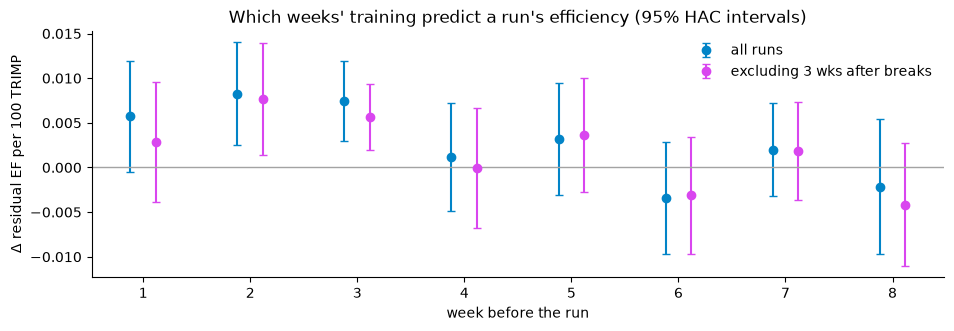

all runs               n=192  weeks 1–2 combined effect +0.0140 (p = 0.009); all 8 lags jointly p = 0.000; R² = 0.190
excluding post-break   n=147  weeks 1–2 combined effect +0.0105 (p = 0.062); all 8 lags jointly p = 0.001; R² = 0.137


In [3]:
load = daily["load"].to_numpy()
cum = np.concatenate([[0.0], np.cumsum(load)])
day_idx = daily.index.get_indexer(runs["localDate"])
LAGS = 8
for lag in range(1, LAGS + 1):
    hi = day_idx - 7 * (lag - 1)          # exclusive end: day before the run, for lag 1
    lo = np.maximum(day_idx - 7 * lag, 0)
    runs[f"load_w{lag}"] = (cum[np.clip(hi, 0, None)] - cum[lo]) / 100  # per 100 TRIMP

lag_cols = [f"load_w{l}" for l in range(1, LAGS + 1)]
usable = runs[day_idx >= 7 * LAGS]  # full 8-week history available

def lag_model(frame):
    return sm.OLS(frame["resid_ef"], sm.add_constant(frame[lag_cols])).fit(cov_type="HAC", cov_kwds={"maxlags": 8})

all_runs = lag_model(usable)
no_breaks = lag_model(usable[~usable["after_break"]])

def coef_table(fit, label):
    ci = fit.conf_int()
    return pd.DataFrame({"week before run": range(1, LAGS + 1), "effect": fit.params[lag_cols].values,
                         "lo": ci.loc[lag_cols, 0].values, "hi": ci.loc[lag_cols, 1].values, "sample": label})

coefs = pd.concat([coef_table(all_runs, "all runs"), coef_table(no_breaks, "excluding 3 wks after breaks")])
fig, ax = plt.subplots()
for (label, g), offset, color in zip(coefs.groupby("sample", sort=False), [-0.12, 0.12], ["#0284c7", "#d946ef"]):
    x = g["week before run"] + offset
    ax.errorbar(x, g["effect"], yerr=[g["effect"] - g["lo"], g["hi"] - g["effect"]], fmt="o", color=color, label=label, capsize=3)
ax.axhline(0, color="#a3a3a3", lw=1)
ax.set_xlabel("week before the run"); ax.set_ylabel("Δ residual EF per 100 TRIMP")
ax.set_title("Which weeks' training predict a run's efficiency (95% HAC intervals)")
ax.legend(frameon=False); plt.show()

for label, fit, n in [("all runs", all_runs, len(usable)), ("excluding post-break", no_breaks, int((~usable["after_break"]).sum()))]:
    weeks12 = fit.params[["load_w1", "load_w2"]].sum()
    test = fit.t_test("load_w1 + load_w2 = 0")
    joint = fit.f_test(", ".join(f"{c} = 0" for c in lag_cols))
    print(f"{label:<22} n={n:<4} weeks 1–2 combined effect {weeks12:+.4f} (p = {float(test.pvalue):.3f}); "
          f"all 8 lags jointly p = {float(joint.pvalue):.3f}; R² = {fit.rsquared:.3f}")

## Test 3: does efficiency predict *next* week's training?

Weekly series: mean residual EF of the week's runs, and weekly TRIMP. Regress next
week's load on this week's residual EF, controlling for the last four weeks of
load (so "you were already training a lot" can't explain it). Then the forward
direction for comparison: this week's load predicting next week's residual EF,
controlling for this week's residual EF.

In [4]:
weekly = pd.DataFrame({
    "load": daily["load"].resample("W-MON", label="left", closed="left").sum(),
})
weekly["resid_ef"] = runs.groupby("week")["resid_ef"].mean().reindex(weekly.index)
weekly["next_load"] = weekly["load"].shift(-1)
weekly["next_ef"] = weekly["resid_ef"].shift(-1)
for k in range(1, 4):
    weekly[f"load_lag{k}"] = weekly["load"].shift(k)
weekly[["load", "next_load"] + [f"load_lag{k}" for k in range(1, 4)]] /= 100  # per 100 TRIMP

rev = smf.ols("next_load ~ resid_ef + load + load_lag1 + load_lag2 + load_lag3", data=weekly.dropna(subset=["resid_ef", "next_load", "load_lag3"])) \
    .fit(cov_type="HAC", cov_kwds={"maxlags": 4})
fwd = smf.ols("next_ef ~ load + resid_ef", data=weekly.dropna(subset=["resid_ef", "next_ef"])) \
    .fit(cov_type="HAC", cov_kwds={"maxlags": 4})

def line(fit, term, unit):
    lo, hi = fit.conf_int().loc[term]
    return f"{fit.params[term]:+.3f} {unit} (95% CI {lo:+.3f} to {hi:+.3f}, p = {fit.pvalues[term]:.3f}, n = {int(fit.nobs)} weeks)"

sd_ef = weekly["resid_ef"].std()
print("Reverse: next week's load per +1 SD of this week's residual EF:")
print("   ", line(rev, "resid_ef", "×100 TRIMP per EF unit"), f"→ {rev.params['resid_ef'] * sd_ef * 100:+.0f} TRIMP per SD")
print("Forward: next week's residual EF per +100 TRIMP this week:")
print("   ", line(fwd, "load", "EF"))

Reverse: next week's load per +1 SD of this week's residual EF:
    +1.531 ×100 TRIMP per EF unit (95% CI -4.498 to +7.560, p = 0.619, n = 93 weeks) → +11 TRIMP per SD
Forward: next week's residual EF per +100 TRIMP this week:
    -0.001 EF (95% CI -0.011 to +0.009, p = 0.864, n = 76 weeks)


## Test 4: efficiency around breaks

Residual EF of runs in the 6 weeks *before* each break started and the 6 weeks
*after* it ended, against each run's own longer-term level (the athlete's median
residual EF over all runs). Reverse causation predicts efficiency already falling
before the break.

        count    mean     sem
side                         
before     51 -0.0241  0.0115
after      73 -0.0362  0.0100
(All-runs mean residual EF is 0 by construction; SD 0.0754)


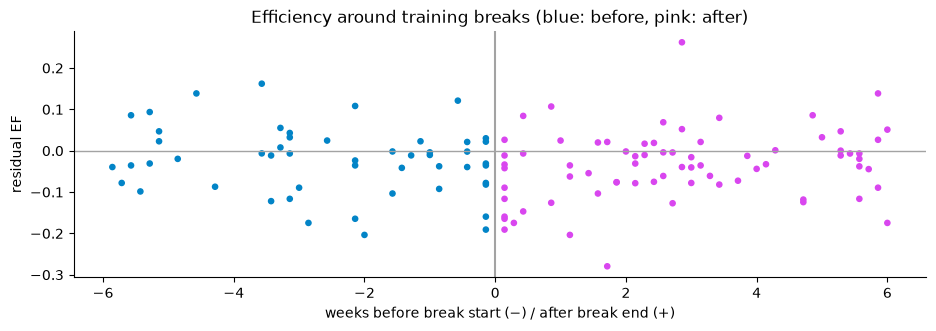

In [5]:
rows = []
for _, b in breaks.iterrows():
    before = runs[(runs["localDate"] < b["start"]) & (runs["localDate"] >= b["start"] - pd.Timedelta(weeks=6))]
    after = runs[(runs["localDate"] > b["end"]) & (runs["localDate"] <= b["end"] + pd.Timedelta(weeks=6))]
    for frame, side in [(before, "before"), (after, "after")]:
        for _, r in frame.iterrows():
            ref = b["start"] if side == "before" else b["end"]
            weeks = (r["localDate"] - ref).days / 7
            rows.append({"break": b["start"].date(), "side": side, "weeks_from_break": weeks, "resid_ef": r["resid_ef"]})
around = pd.DataFrame(rows)
summary = around.groupby("side")["resid_ef"].agg(["count", "mean", "sem"]).reindex(["before", "after"])
print(summary.round(4).to_string())
print(f"(All-runs mean residual EF is 0 by construction; SD {runs['resid_ef'].std():.4f})")

ax = around.plot.scatter(x="weeks_from_break", y="resid_ef", c=np.where(around["side"] == "before", "#0284c7", "#d946ef"), s=14)
ax.axvline(0, color="#a3a3a3"); ax.axhline(0, color="#a3a3a3", lw=1)
ax.set_xlabel("weeks before break start (−) / after break end (+)"); ax.set_ylabel("residual EF")
ax.set_title("Efficiency around training breaks (blue: before, pink: after)")
plt.show()

## Conclusions

**Test 1: the effect is real, and it's recent.** Load in the two weeks before a run
predicts its residual efficiency: +0.014 EF per 100 TRIMP (p = 0.009), and the eight
weekly lags are jointly significant (p < 0.001). This agrees with 01b's single
~13-day load term.

**Test 2: breaks explain part of it, not all.** Dropping the 45 runs in the three
weeks after a break shrinks the two-week effect by about a quarter, to +0.0105
(p = 0.06), but the lags remain jointly significant (p = 0.001).

**Test 3: uninformative.** At weekly resolution, neither direction shows a
relationship (both p > 0.6). Weekly EF is too noisy (signal-to-noise below 1, per the
audit), so this test lacks the power to support or rule out reverse causation.

**Test 4: efficiency is already down before breaks.** Runs in the six weeks before a
break average −0.024 residual EF (± 0.012), and runs in the six weeks after average
−0.036 (± 0.010). The pre-break dip fits something (illness, accumulated fatigue,
life stress) lowering efficiency before training stops. The deeper post-break dip
fits detraining.

**Overall: both stories are partly true.** There's a short-term training effect that
survives excluding breaks, and there's evidence that some of the load–efficiency
link comes from whatever causes breaks also lowering efficiency beforehand.
Observational data can't apportion the two precisely.

**Caveat:** heart-rate recording starts on 7 April 2024, so the seven runs before it
score zero TRIMP and loads for April–May 2024 are slightly undercounted.